# Synthetic timing demonstration

**This notebook does not implement or validate Trend R3.** Prices and event timestamps are hand-authored teaching inputs. The example distinguishes the historical coordinate of an annotation from its actual availability, then checks future-window eligibility.

No private source, data, formulas, or production settings are read. The bar count, split, and horizon below belong only to this constructed example.

In [1]:
from pathlib import Path
import sys
import platform
import matplotlib
from IPython.display import display, Markdown, Image
from io import BytesIO

root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
assert (root / 'demo/timing_demo.py').exists()
sys.path.insert(0, str(root))
from demo.timing_demo import synthetic_example, available_events, write_snapshot
print({'Python': platform.python_version(), 'matplotlib': matplotlib.__version__})

{'Python': '3.12.14', 'matplotlib': '3.11.2'}


## Availability follows confirmation

The supplied event log records where an annotation is drawn and when it becomes available. There is no signal-detection algorithm in this example.

In [2]:
prices, events = synthetic_example()
for bar in (8, 11, 12, 28):
    print(f"Through bar {bar}: {[e['event_id'] for e in available_events(events, bar)]}")
assert available_events(events, 11) == []
assert [e['event_id'] for e in available_events(events, 12)] == ['A']

Through bar 8: []
Through bar 11: []
Through bar 12: ['A']
Through bar 28: ['A', 'B']


## Complete target windows and split discipline

Targets begin after confirmation. A development event is purged if its future window reaches the holdout; a tail event is excluded if its window is incomplete. These are eligibility checks, not estimates of predictive usefulness.

In [3]:
rows, fig = write_snapshot(root)
header = '| Event | Anchor | Confirmation | Delay | Future window | Eligibility |\n|---|---:|---:|---:|---|---|'
body = '\n'.join(f"| {r['event_id']} | {r['anchor_bar']} | {r['confirmed_bar']} | {r['confirmation_delay_bars']} | {r['target_start_bar']}–{r['target_end_bar']} | {r['status']} |" for r in rows)
display(Markdown(header + '\n' + body))
assert [r['status'] for r in rows] == ['development', 'development', 'purged_at_split', 'holdout', 'excluded_incomplete_future']

| Event | Anchor | Confirmation | Delay | Future window | Eligibility |
|---|---:|---:|---:|---|---|
| A | 8 | 12 | 4 | 13–20 | development |
| B | 24 | 28 | 4 | 29–36 | development |
| C | 40 | 51 | 11 | 52–59 | purged_at_split |
| D | 53 | 59 | 6 | 60–67 | holdout |
| E | 72 | 76 | 4 | 77–84 | excluded_incomplete_future |

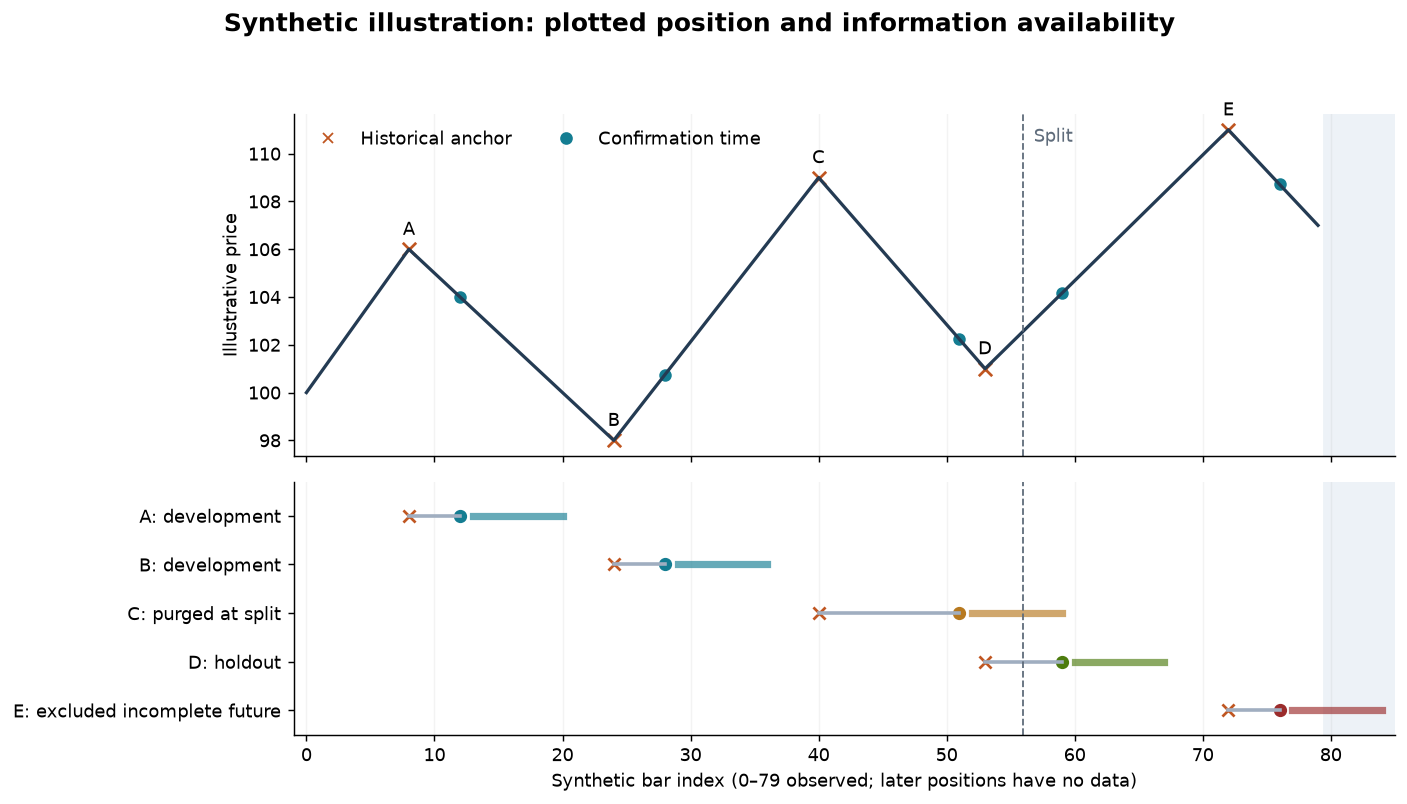

In [4]:
import matplotlib.pyplot as plt
buffer = BytesIO()
fig.savefig(buffer, format='png', dpi=130, bbox_inches='tight')
display(Image(data=buffer.getvalue()))
plt.close(fig)

## Interpretation

The example contains five constructed events: two eligible development events, one purged event, one eligible holdout event, and one event with an incomplete future window. No return, hit rate, or uncertainty interval is estimated from this small illustration.

These checks concern an event log supplied to the public example. They do not establish whether Trend R3 generates the correct events, avoids all historical changes, matches a separate implementation, or predicts prices. See [the evidence status](../results/evidence_status.md) before interpreting this notebook as evidence about the indicator.